<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Merged data shape: (763, 49)
Duplicate patient_id rows: 0

Target distribution:
HPV
0    191
1    141
Name: count, dtype: int64

Predictors: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
Final dataset shape: (332, 8)

Split sizes:
Train:      215 (64.8%)
Validation: 50 (15.1%)
Test:       67 (20.2%)

Class counts:
Train:
 HPV
0    123
1     92
Name: count, dtype: int64
Validation:
 HPV
0    29
1    21
Name: count, dtype: int64
Test:
 HPV
0    39
1    28
Name: count, dtype: int64

Number of original predictors: 6
Number of encoded ANN input features: 19

ANN architecture:
ANN(
  (network): Sequential(
    (0): Linear(in_features=19, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features

,Model,Checkpoint_Selection,Selected_Epoch,Test_Loss,N_Train,N_Validation,N_Test,Original_Predictor_Count,Encoded_Feature_Count,ROC_AUC,PR_AUC,BA,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,ANN,Best_Validation_Loss,63,0.572847,215,50,67,6,19,0.778388,0.736999,0.668040,0.701493,0.722222,0.464286,0.565217,34,5,15,13
1,ANN,Best_Validation_BA,59,0.575457,215,50,67,6,19,0.774725,0.734802,0.690934,0.716418,0.714286,0.535714,0.612245,33,6,13,15
2,ANN,Best_Validation_ROC_AUC,70,0.575324,215,50,67,6,19,0.782051,0.741792,0.668040,0.701493,0.722222,0.464286,0.565217,34,5,15,13
3,ANN,Best_Validation_PR_AUC,89,0.555097,215,50,67,6,19,0.800366,0.774424,0.703755,0.731343,0.750000,0.535714,0.625000,34,5,13,15


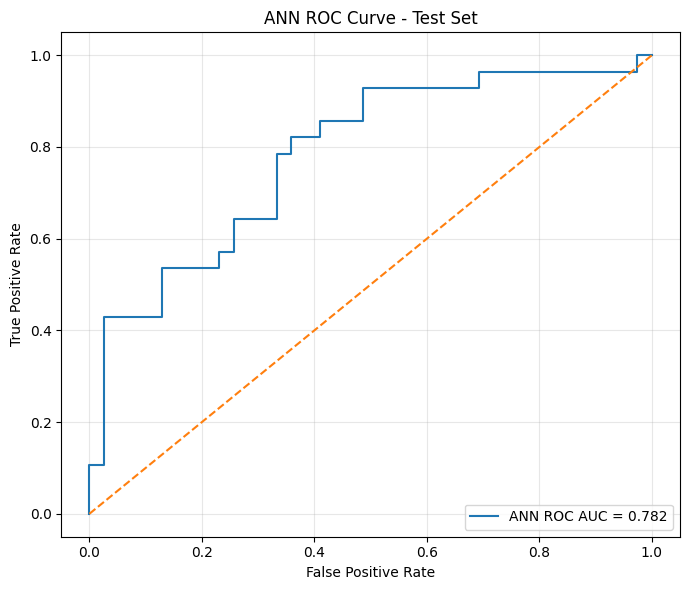

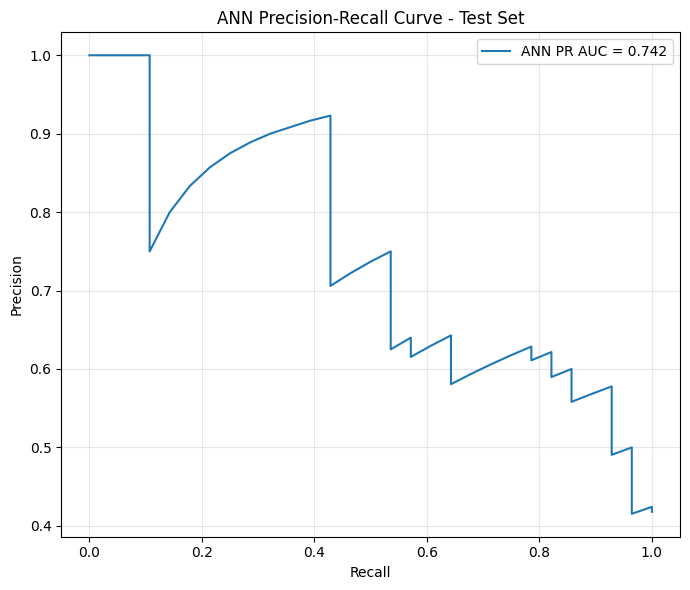


================ ANN SUMMARY ================
Predictors:
 - age_at_initial_diagnosis
 - sex
 - smoking_status
 - primary_tumor_site
 - primarily_metastasis
 - pN_stage

Target: HPV
  0 = HPV negative
  1 = HPV positive

Split:
  Train:      65%
  Validation: 15%
  Test:       20%

Metrics saved:
  ROC AUC
  PR AUC (Average Precision)
  Balanced Accuracy (BA)
  Accuracy, Precision, Recall, F1
  Confusion matrix counts (TN, FP, FN, TP)

Files saved in: /content/drive/MyDrive/ANN_results
  ANN_results.csv
  ANN_epoch_history.csv
  ANN_test_predictions.csv


In [2]:

# ============================================================
# 1. IMPORT LIBRARIES AND SET RANDOM SEEDS
# ============================================================

import os
import random
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    log_loss
)
from sklearn.metrics import roc_curve, precision_recall_curve

import matplotlib.pyplot as plt


# Reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# ============================================================
# 2. LOAD AND MERGE DATA
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

clinical_data = pd.read_json(
    '/content/drive/MyDrive/clinical_data.json'
)

pathological_data = pd.read_json(
    '/content/drive/MyDrive/pathological_data.json'
)

# Merge on patient_id
data = pd.merge(
    clinical_data,
    pathological_data,
    on='patient_id',
    how='inner',
    suffixes=('', '_path')
)

print("Merged data shape:", data.shape)
print("Duplicate patient_id rows:", data['patient_id'].duplicated().sum())


# ============================================================
# 3. SELECT TARGET AND SIX PREDICTORS
# ============================================================

# Target
target_col = 'hpv_association_p16'

if target_col not in data.columns:
    raise ValueError(
        f"Target column '{target_col}' not found. "
        f"Available columns: {data.columns.tolist()}"
    )

# Normalize target labels
target_normalized = (
    data[target_col]
    .astype(str)
    .str.strip()
    .str.lower()
)

data = data.loc[
    target_normalized.isin(['positive', 'negative'])
].copy()

data['HPV'] = (
    data[target_col]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'negative': 0, 'positive': 1})
)

# The six predictors used by GPT-2
feature_cols = [
    'age_at_initial_diagnosis',
    'sex',
    'smoking_status',
    'primary_tumor_site',
    'primarily_metastasis',
    'pN_stage'
]

# Handle common alternative names for pN stage
if 'pN_stage' not in data.columns:
    alternatives = [
        'pathological_N_stage',
        'pathologic_N_stage',
        'pathological_n_stage',
        'pN'
    ]

    matched = next(
        (col for col in alternatives if col in data.columns),
        None
    )

    if matched is not None:
        data = data.rename(columns={matched: 'pN_stage'})
        print(f"Using '{matched}' as 'pN_stage'.")

missing_cols = [
    col for col in feature_cols
    if col not in data.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required predictors: {missing_cols}\n"
        f"Available columns: {data.columns.tolist()}"
    )

# Keep only patient ID, predictors, and target
data = data[
    ['patient_id'] + feature_cols + ['HPV']
].copy()

# Remove rows without a valid target
data = data.dropna(subset=['HPV']).copy()
data['HPV'] = data['HPV'].astype(int)

# Treat categorical predictors as categorical values
categorical_features = [
    'sex',
    'smoking_status',
    'primary_tumor_site',
    'primarily_metastasis',
    'pN_stage'
]

numeric_features = ['age_at_initial_diagnosis']

for col in categorical_features:
    data[col] = data[col].apply(
        lambda x: str(x).strip() if pd.notna(x) else np.nan
    )

# Convert age to numeric
data['age_at_initial_diagnosis'] = pd.to_numeric(
    data['age_at_initial_diagnosis'],
    errors='coerce'
)

# Remove duplicate patient rows so one patient cannot appear
# multiple times in the split.
# If duplicates have conflicting records, investigate them first.
data = data.drop_duplicates(subset=['patient_id'], keep='first').copy()

print("\nTarget distribution:")
print(data['HPV'].value_counts().sort_index())
print("\nPredictors:", feature_cols)
print("Final dataset shape:", data.shape)


# ============================================================
# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
#    65% TRAIN / 15% VALIDATION / 20% TEST
# ============================================================

X = data[feature_cols].copy()
y = data['HPV'].copy()
patient_ids = data['patient_id'].copy()

# First reserve 20% for the final test set
X_train_val, X_test, y_train_val, y_test, ids_train_val, ids_test = (
    train_test_split(
        X,
        y,
        patient_ids,
        test_size=0.20,
        random_state=seed,
        stratify=y
    )
)

# Validation is 15% of the full dataset:
# 15 / 80 = 0.1875 of the remaining 80%
X_train, X_val, y_train, y_val, ids_train, ids_val = (
    train_test_split(
        X_train_val,
        y_train_val,
        ids_train_val,
        test_size=0.1875,
        random_state=seed,
        stratify=y_train_val
    )
)

print("\nSplit sizes:")
print(f"Train:      {len(X_train)} ({len(X_train) / len(data):.1%})")
print(f"Validation: {len(X_val)} ({len(X_val) / len(data):.1%})")
print(f"Test:       {len(X_test)} ({len(X_test) / len(data):.1%})")

print("\nClass counts:")
print("Train:\n", y_train.value_counts().sort_index())
print("Validation:\n", y_val.value_counts().sort_index())
print("Test:\n", y_test.value_counts().sort_index())

# Check that the patient splits do not overlap
assert set(ids_train).isdisjoint(set(ids_val))
assert set(ids_train).isdisjoint(set(ids_test))
assert set(ids_val).isdisjoint(set(ids_test))


# ============================================================
# 5. PREPROCESS FEATURES
#    Fit imputers, scaler, and encoder on TRAIN ONLY
# ============================================================

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse output to dense arrays if necessary
if hasattr(X_train_processed, 'toarray'):
    X_train_processed = X_train_processed.toarray()
if hasattr(X_val_processed, 'toarray'):
    X_val_processed = X_val_processed.toarray()
if hasattr(X_test_processed, 'toarray'):
    X_test_processed = X_test_processed.toarray()

X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

X_train_tensor = torch.tensor(
    X_train_processed, dtype=torch.float32
).to(device)
X_val_tensor = torch.tensor(
    X_val_processed, dtype=torch.float32
).to(device)
X_test_tensor = torch.tensor(
    X_test_processed, dtype=torch.float32
).to(device)

y_train_tensor = torch.tensor(
    y_train_np, dtype=torch.long
).to(device)
y_val_tensor = torch.tensor(
    y_val_np, dtype=torch.long
).to(device)
y_test_tensor = torch.tensor(
    y_test_np, dtype=torch.long
).to(device)

n_features = X_train_processed.shape[1]
n_classes = 2

print("\nNumber of original predictors:", len(feature_cols))
print("Number of encoded ANN input features:", n_features)


# ============================================================
# 6. DEFINE ANN ARCHITECTURE
# ============================================================

class ANN(nn.Module):
    def __init__(self, input_dim, num_classes=2):
        super(ANN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, num_classes)
        )

    def forward(self, x):
        return self.network(x)


model = ANN(
    input_dim=n_features,
    num_classes=n_classes
).to(device)

print("\nANN architecture:")
print(model)


# ============================================================
# 7. LOSS FUNCTION AND OPTIMIZER
# ============================================================

# Class-weighted loss, calculated using TRAIN labels only
class_counts = np.bincount(y_train_np, minlength=2)

if np.any(class_counts == 0):
    raise ValueError(
        "Training split is missing one of the target classes."
    )

class_weights = len(y_train_np) / (
    len(class_counts) * class_counts
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 500


# ============================================================
# 8. METRIC HELPER
# ============================================================

def calculate_metrics(y_true, y_prob, threshold=0.5):
    """
    y_prob is the predicted probability of HPV-positive (class 1).
    PR AUC is calculated as Average Precision.
    """

    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)

    metrics = {
        'ROC_AUC': np.nan,
        'PR_AUC': np.nan,
        'BA': balanced_accuracy_score(y_true, y_pred),
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1': f1_score(
            y_true, y_pred, zero_division=0
        )
    }

    # AUC metrics require both classes in the evaluation set
    if len(np.unique(y_true)) == 2:
        metrics['ROC_AUC'] = roc_auc_score(y_true, y_prob)
        metrics['PR_AUC'] = average_precision_score(
            y_true, y_prob
        )

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    metrics.update({
        'TN': int(tn),
        'FP': int(fp),
        'FN': int(fn),
        'TP': int(tp)
    })

    return metrics


# ============================================================
# 9. TRAIN MODEL
#    Checkpoint selection uses VALIDATION metrics only
# ============================================================

best_val_loss = float('inf')
best_val_ba = -float('inf')
best_val_roc_auc = -float('inf')
best_val_pr_auc = -float('inf')

best_loss_state = None
best_ba_state = None
best_roc_state = None
best_pr_state = None

best_loss_epoch = None
best_ba_epoch = None
best_roc_epoch = None
best_pr_epoch = None

history = []

for epoch in range(epochs):

    # -----------------------
    # Training
    # -----------------------
    model.train()

    optimizer.zero_grad()

    train_logits = model(X_train_tensor)
    train_loss = criterion(
        train_logits,
        y_train_tensor
    )

    train_loss.backward()
    optimizer.step()

    # -----------------------
    # Validation
    # -----------------------
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_tensor)

        val_loss = criterion(
            val_logits,
            y_val_tensor
        ).item()

        val_prob = torch.softmax(
            val_logits,
            dim=1
        )[:, 1].cpu().numpy()

    train_prob = torch.softmax(
        train_logits.detach(),
        dim=1
    )[:, 1].cpu().numpy()

    train_metrics = calculate_metrics(
        y_train_np,
        train_prob
    )

    val_metrics = calculate_metrics(
        y_val_np,
        val_prob
    )

    history.append({
        'Epoch': epoch + 1,
        'Train_Loss': float(train_loss.item()),
        'Validation_Loss': float(val_loss),

        'Train_ROC_AUC': train_metrics['ROC_AUC'],
        'Train_PR_AUC': train_metrics['PR_AUC'],
        'Train_BA': train_metrics['BA'],

        'Validation_ROC_AUC': val_metrics['ROC_AUC'],
        'Validation_PR_AUC': val_metrics['PR_AUC'],
        'Validation_BA': val_metrics['BA']
    })

    # Save best validation-loss checkpoint
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_loss_epoch = epoch + 1
        best_loss_state = copy.deepcopy(model.state_dict())

    # Save best validation-BA checkpoint
    if val_metrics['BA'] > best_val_ba:
        best_val_ba = val_metrics['BA']
        best_ba_epoch = epoch + 1
        best_ba_state = copy.deepcopy(model.state_dict())

    # Save best validation ROC AUC checkpoint
    if (
        not np.isnan(val_metrics['ROC_AUC'])
        and val_metrics['ROC_AUC'] > best_val_roc_auc
    ):
        best_val_roc_auc = val_metrics['ROC_AUC']
        best_roc_epoch = epoch + 1
        best_roc_state = copy.deepcopy(model.state_dict())

    # Save best validation PR AUC checkpoint
    if (
        not np.isnan(val_metrics['PR_AUC'])
        and val_metrics['PR_AUC'] > best_val_pr_auc
    ):
        best_val_pr_auc = val_metrics['PR_AUC']
        best_pr_epoch = epoch + 1
        best_pr_state = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 25 == 0 or epoch == 0:
        print(
            f"Epoch [{epoch + 1:03d}/{epochs}] "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val ROC AUC: {val_metrics['ROC_AUC']:.4f} | "
            f"Val PR AUC: {val_metrics['PR_AUC']:.4f} | "
            f"Val BA: {val_metrics['BA']:.4f}"
        )

print("\nTraining complete.")
print("Best validation-loss epoch:", best_loss_epoch)
print("Best validation-BA epoch:", best_ba_epoch)
print("Best validation-ROC-AUC epoch:", best_roc_epoch)
print("Best validation-PR-AUC epoch:", best_pr_epoch)


# ============================================================
# 10. SAVE EPOCH HISTORY TO CSV
# ============================================================

output_dir = '/content/drive/MyDrive/ANN_results'
os.makedirs(output_dir, exist_ok=True)

history_df = pd.DataFrame(history)

history_path = os.path.join(
    output_dir,
    'ANN_epoch_history.csv'
)

history_df.to_csv(history_path, index=False)

print("\nSaved epoch history to:")
print(history_path)


# ============================================================
# 11. EVALUATE SAVED CHECKPOINTS ON TEST SET
#     Test data is not used for checkpoint selection
# ============================================================

checkpoint_states = {
    'Best_Validation_Loss': (
        best_loss_state, best_loss_epoch
    ),
    'Best_Validation_BA': (
        best_ba_state, best_ba_epoch
    ),
    'Best_Validation_ROC_AUC': (
        best_roc_state, best_roc_epoch
    ),
    'Best_Validation_PR_AUC': (
        best_pr_state, best_pr_epoch
    )
}

results = []
test_predictions = []

for selection_name, (state, selected_epoch) in checkpoint_states.items():

    if state is None:
        print(
            f"Skipping {selection_name}: "
            "no checkpoint was saved."
        )
        continue

    model.load_state_dict(state)
    model.eval()

    with torch.no_grad():
        test_logits = model(X_test_tensor)

        test_prob = torch.softmax(
            test_logits,
            dim=1
        )[:, 1].cpu().numpy()

        test_loss = criterion(
            test_logits,
            y_test_tensor
        ).item()

    test_metrics = calculate_metrics(
        y_test_np,
        test_prob
    )

    row = {
        'Model': 'ANN',
        'Checkpoint_Selection': selection_name,
        'Selected_Epoch': selected_epoch,
        'Test_Loss': float(test_loss),
        'N_Train': len(X_train),
        'N_Validation': len(X_val),
        'N_Test': len(X_test),
        'Original_Predictor_Count': len(feature_cols),
        'Encoded_Feature_Count': n_features,
        **test_metrics
    }

    results.append(row)

    # Save per-patient test predictions
    for i, (patient_id, true_label, probability) in enumerate(
        zip(ids_test.to_numpy(), y_test_np, test_prob)
    ):
        test_predictions.append({
            'Model': 'ANN',
            'Checkpoint_Selection': selection_name,
            'Selected_Epoch': selected_epoch,
            'patient_id': patient_id,
            'y_true': int(true_label),
            'y_prob_HPV_positive': float(probability),
            'y_pred_threshold_0.5': int(probability >= 0.5)
        })

    print(f"\n{selection_name} (epoch {selected_epoch})")
    print(f"  Test ROC AUC: {test_metrics['ROC_AUC']:.4f}")
    print(f"  Test PR AUC:  {test_metrics['PR_AUC']:.4f}")
    print(f"  Test BA:      {test_metrics['BA']:.4f}")


# ============================================================
# 12. SAVE TEST METRICS AND PREDICTIONS TO CSV
# ============================================================

results_df = pd.DataFrame(results)

results_path = os.path.join(
    output_dir,
    'ANN_results.csv'
)

results_df.to_csv(results_path, index=False)

predictions_df = pd.DataFrame(test_predictions)

predictions_path = os.path.join(
    output_dir,
    'ANN_test_predictions.csv'
)

predictions_df.to_csv(
    predictions_path,
    index=False
)

print("\nSaved test results to:")
print(results_path)

print("\nSaved test predictions to:")
print(predictions_path)

print("\nTest-set results:")
display(results_df)


# ============================================================
# 13. PLOT ROC CURVE AND PRECISION-RECALL CURVE
#     Using the best validation ROC-AUC checkpoint
# ============================================================

if best_roc_state is not None:
    model.load_state_dict(best_roc_state)
    model.eval()

    with torch.no_grad():
        test_logits = model(X_test_tensor)
        best_roc_test_prob = torch.softmax(
            test_logits,
            dim=1
        )[:, 1].cpu().numpy()

    # ROC curve
    fpr, tpr, _ = roc_curve(
        y_test_np,
        best_roc_test_prob
    )

    roc_auc_value = roc_auc_score(
        y_test_np,
        best_roc_test_prob
    )

    plt.figure(figsize=(7, 6))
    plt.plot(
        fpr,
        tpr,
        label=f'ANN ROC AUC = {roc_auc_value:.3f}'
    )
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ANN ROC Curve - Test Set')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Precision-recall curve
    precision, recall, _ = precision_recall_curve(
        y_test_np,
        best_roc_test_prob
    )

    pr_auc_value = average_precision_score(
        y_test_np,
        best_roc_test_prob
    )

    plt.figure(figsize=(7, 6))
    plt.plot(
        recall,
        precision,
        label=f'ANN PR AUC = {pr_auc_value:.3f}'
    )
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('ANN Precision-Recall Curve - Test Set')
    plt.legend(loc='best')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n================ ANN SUMMARY ================")
print("Predictors:")
for feature in feature_cols:
    print(" -", feature)

print("\nTarget: HPV")
print("  0 = HPV negative")
print("  1 = HPV positive")

print("\nSplit:")
print("  Train:      65%")
print("  Validation: 15%")
print("  Test:       20%")

print("\nMetrics saved:")
print("  ROC AUC")
print("  PR AUC (Average Precision)")
print("  Balanced Accuracy (BA)")
print("  Accuracy, Precision, Recall, F1")
print("  Confusion matrix counts (TN, FP, FN, TP)")

print("\nFiles saved in:", output_dir)
print("  ANN_results.csv")
print("  ANN_epoch_history.csv")
print("  ANN_test_predictions.csv")
